# Rol 1 — Analista de Incertidumbre e Información
**Proyecto Retador: Patrones Invisibles — Información, Incertidumbre y Movilidad Urbana**
ML No Supervisado · Universidad de La Sabana · 2026-II

**Pregunta de negocio para UrbanMove:** *¿Qué tan predecible es la demanda según la zona, la hora y el tipo de día, y cuánta información aporta cada variable para decidir dónde posicionar conductores?*

Este notebook aplica, **con números propios de la muestra de 50 000 viajes**, los ocho conceptos del bloque:

| # | Concepto | Pregunta que responde para UrbanMove |
|---|---|---|
| 1 | Probabilidad (distribuciones empíricas, suavizado) | ¿Cómo se reparte la demanda entre zonas y horas? |
| 2 | Entropía de Shannon | ¿Qué tan concentrada/caótica es la demanda en cada franja? |
| 3 | Entropía condicional | ¿Cuánta incertidumbre del destino queda si ya sé el origen o la hora? |
| 4 | Información mutua | ¿Cuántos bits aporta la hora (u origen) sobre la zona de destino? |
| 5 | Divergencia KL | ¿Qué tan distinta es la demanda laboral vs. fin de semana? |
| 6 | Entropía cruzada | ¿Cuánto cuesta usar el modelo equivocado (laboral para fin de semana)? |
| 7 | Desigualdad de Jensen | ¿Por qué el ETA calculado con la velocidad promedio subestima el tiempo real? |
| 8 | Log-sum-exp trick | ¿Cómo combinar probabilidades de miles de viajes y 20 zonas sin *underflow*? (puente al Rol 3) |

**Unidades:** todas las entropías se reportan en **bits** (logaritmo base 2).

**Zonificación:** grid geográfico de ~1.7 km × 1.7 km (ver `utils.py`); las 19 celdas con ≥ 0.5 % de los pickups se conservan como zonas y el resto se agrupa en `Otras` → **K = 20 zonas**. Las etiquetas de barrio son aproximadas (centro de la celda).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.special import logsumexp
import utils
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(utils.SEMILLA)

df = utils.cargar_muestra()
ZONAS = sorted(df.zona_pickup.unique())
FRANJAS = list(utils.FRANJAS.keys())
print(df.shape, "| zonas:", len(ZONAS))
df[["pickup_datetime", "hora", "franja", "fin_de_semana", "zona_pickup", "zona_dropoff", "dist_km", "duracion_min"]].head()

(50000, 25) | zonas: 20


,pickup_datetime,hora,franja,fin_de_semana,zona_pickup,zona_dropoff,dist_km,duracion_min
0,2016-01-17 01:04:10,1,Madrugada (0-5h),1,Otras,Otras,7.025000,15.250000
1,2016-05-21 23:26:08,23,Noche (20-23h),1,Z02 Midtown Este/Grand Central,Otras,6.207727,19.833333
2,2016-03-08 07:27:01,7,Pico AM (6-9h),0,Z00 Midtown Oeste/Penn Station,Z01 Chelsea/Flatiron,1.262128,5.066667
3,2016-02-24 22:05:09,22,Noche (20-23h),0,Z02 Midtown Este/Grand Central,Z00 Midtown Oeste/Penn Station,1.906100,9.566667
4,2016-06-11 03:55:35,3,Madrugada (0-5h),1,Z01 Chelsea/Flatiron,Z02 Midtown Este/Grand Central,2.185868,3.800000


## 0. Funciones base (implementadas a mano, sin librerías de teoría de la información)

- Entropía: $H(X) = -\sum_x p(x)\log_2 p(x)$
- Entropía conjunta y condicional: $H(Y\mid X) = H(X,Y) - H(X)$ (regla de la cadena)
- Información mutua: $I(X;Y) = H(Y) - H(Y\mid X) = \sum_{x,y} p(x,y)\log_2\frac{p(x,y)}{p(x)p(y)}$
- KL: $D_{KL}(P\|Q) = \sum_x p(x)\log_2\frac{p(x)}{q(x)}$ ; Entropía cruzada: $H(P,Q) = -\sum_x p(x)\log_2 q(x) = H(P) + D_{KL}(P\|Q)$

Para KL y entropía cruzada usamos **suavizado de Laplace** ($\alpha=1$) en $Q$: si una zona tiene 0 viajes en $Q$ y >0 en $P$, la KL sería infinita — un artefacto muestral, no un hecho de negocio.

In [2]:
def distribucion(serie, soporte, alpha=0.0):
    # Probabilidad empírica sobre un soporte fijo, con suavizado de Laplace opcional
    c = serie.value_counts().reindex(soporte, fill_value=0).astype(float)
    return (c + alpha) / (c.sum() + alpha * len(soporte))

def entropia(p):
    p = np.asarray(p, float); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def entropia_conjunta(x, y):
    return entropia(pd.crosstab(x, y).values.ravel() / len(x))

def entropia_condicional(y, x):          # H(Y | X)
    return entropia_conjunta(x, y) - entropia(x.value_counts(normalize=True))

def info_mutua(x, y):                    # I(X;Y) = H(Y) - H(Y|X)
    return entropia(y.value_counts(normalize=True)) - entropia_condicional(y, x)

def kl(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float); m = p > 0
    return float((p[m] * np.log2(p[m] / q[m])).sum())

def entropia_cruzada(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float); m = p > 0
    return float(-(p[m] * np.log2(q[m])).sum())

# Verificación rápida con un caso de libro: moneda justa = 1 bit, dado justo = log2(6)
print(entropia([.5, .5]), entropia(np.ones(6) / 6), np.log2(6))

1.0 2.584962500721156 2.584962500721156


## 1. Probabilidad: ¿cómo se reparte la demanda?
Estimamos $P(\text{zona de recogida})$ y $P(\text{zona}\mid\text{franja})$ como frecuencias relativas. Con 50 000 viajes y 20 zonas, el error estándar de cada probabilidad es a lo sumo $\sqrt{0.25/50000}\approx 0.22$ puntos porcentuales.

In [3]:
p_zona = distribucion(df.zona_pickup, ZONAS)
p_franja = df.franja.value_counts(normalize=True).reindex(FRANJAS)
tabla_prob = pd.DataFrame({"P(zona)": p_zona, "viajes": df.zona_pickup.value_counts()}).sort_values("P(zona)", ascending=False)
print(tabla_prob.round(4).to_string())
print("\nP(franja):\n", p_franja.round(4).to_string())
top5 = tabla_prob["P(zona)"].head(5).sum()
print(f"\nLas 5 zonas más demandadas concentran {top5:.1%} de los pickups (20 zonas en total).")

                                    P(zona)  viajes
zona_pickup                                        
Z00 Midtown Oeste/Penn Station       0.1342    6710
Z01 Chelsea/Flatiron                 0.1100    5500
Z02 Midtown Este/Grand Central       0.0994    4969
Z03 Upper East Side Sur              0.0934    4668
Z04 Columbus Circle/Hell's Kitchen   0.0765    3824
Z05 East Village/LES                 0.0666    3329
Otras                                0.0559    2794
Z06 Upper East Side Norte            0.0517    2586
Z07 West Village                     0.0445    2226
Z08 Lenox Hill (UES)                 0.0422    2112
Z09 Central Park/UWS                 0.0417    2087
Z10 SoHo/Tribeca                     0.0335    1674
Z11 Financial District               0.0303    1516
Z12 Aeropuerto LaGuardia             0.0251    1256
Z13 Upper West Side Norte            0.0233    1167
Z14 Upper West Side                  0.0183     917
Z15 Aeropuerto JFK                   0.0162     811
Z16 Gramercy

**Lectura para UrbanMove.** La demanda está fuertemente sesgada hacia Manhattan central: *Midtown Oeste/Penn Station* sola capta el **13.4 %** de los pickups y las **5 zonas principales concentran el 51.3 %** (de 20). Los aeropuertos pesan poco en volumen (LaGuardia 2.5 %, JFK 1.6 %), pero —como muestra el Rol 2— generan los viajes más largos.

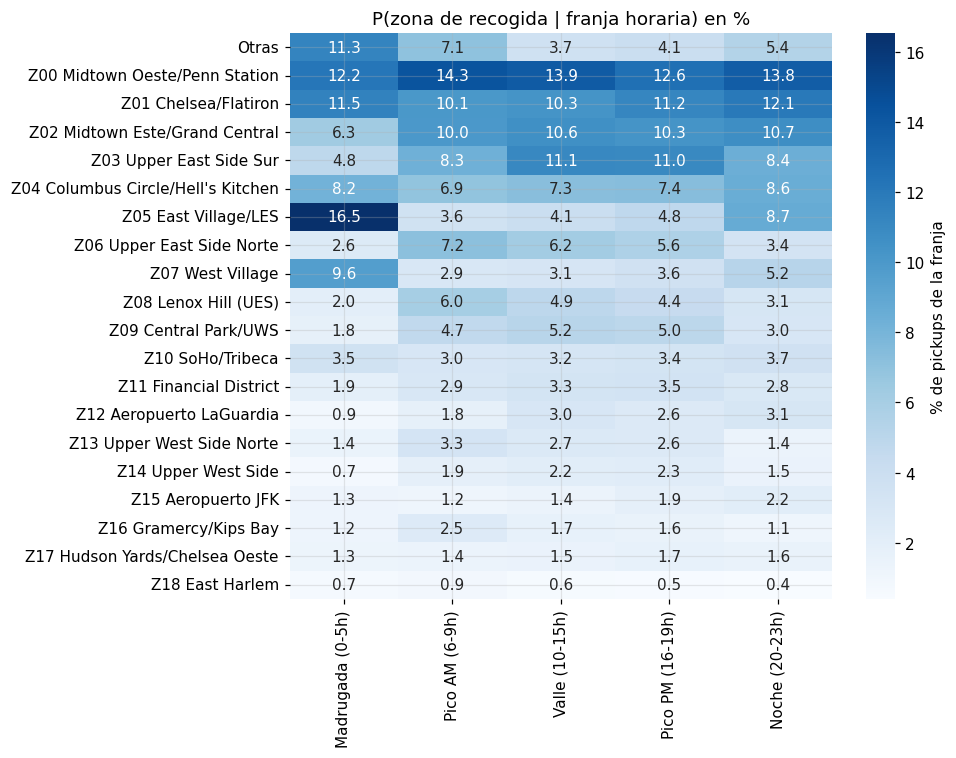

In [4]:
p_zona_franja = pd.crosstab(df.zona_pickup, df.franja, normalize="columns").reindex(index=ZONAS, columns=FRANJAS)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(p_zona_franja * 100, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% de pickups de la franja"}, ax=ax)
ax.set_title("P(zona de recogida | franja horaria) en %"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("figuras/rol1_p_zona_franja.png", bbox_inches="tight"); plt.show()

**Lo que cambia entre franjas.** En la **madrugada** la demanda se desplaza a zonas de vida nocturna: *East Village/LES* pasa de 3.6 % (pico AM) a **16.5 %** y *West Village* de 2.9 % a **9.6 %**, mientras las zonas residenciales del Upper East/West Side caen a 1–3 %. En el **pico AM** ganan peso las zonas residenciales (UES Norte 7.2 %, Lenox Hill 6.0 %): son el origen del commuter.

## 2. Entropía de Shannon: ¿qué tan concentrada está la demanda?
- $H_{max} = \log_2 20 = 4.32$ bits (demanda uniforme en las 20 zonas).
- **Perplejidad** $2^{H}$ = número de *zonas efectivas* entre las que se reparte la demanda: una traducción directa a flota.
- Intervalos de confianza al 95 % por **bootstrap** (500 remuestreos) — UrbanMove pidió números defendibles.

In [5]:
def boot_ci(fun, datos, B=500, seed=0):
    r = np.random.default_rng(seed); n = len(datos)
    vals = [fun(datos.iloc[r.integers(0, n, n)]) for _ in range(B)]
    return np.percentile(vals, [2.5, 97.5])

H_max = np.log2(len(ZONAS))
filas = []
def H_zona(d): return entropia(d.zona_pickup.value_counts(normalize=True))
grupos = [("Global", df)] + [(f, df[df.franja == f]) for f in FRANJAS] + \
         [("Día laboral (L-V)", df[df.fin_de_semana == 0]), ("Fin de semana (S-D)", df[df.fin_de_semana == 1])]
for nombre, d in grupos:
    h = H_zona(d); lo, hi = boot_ci(H_zona, d)
    filas.append([nombre, len(d), h, lo, hi, h / H_max, 2 ** h])
tabla_H = pd.DataFrame(filas, columns=["Contexto", "n", "H (bits)", "IC95 inf", "IC95 sup", "H/Hmax", "Zonas efectivas 2^H"])
print(f"H_max = log2({len(ZONAS)}) = {H_max:.3f} bits")
print(tabla_H.round(3).to_string(index=False))

H_max = log2(20) = 4.322 bits
           Contexto     n  H (bits)  IC95 inf  IC95 sup  H/Hmax  Zonas efectivas 2^H
             Global 50000     3.981     3.973     3.988   0.921               15.788
   Madrugada (0-5h)  6002     3.725     3.696     3.753   0.862               13.227
     Pico AM (6-9h)  7615     3.978     3.955     3.999   0.920               15.753
     Valle (10-15h) 14408     3.965     3.950     3.980   0.917               15.614
   Pico PM (16-19h) 11074     3.987     3.970     4.003   0.923               15.861
     Noche (20-23h) 10901     3.909     3.889     3.923   0.904               15.023
  Día laboral (L-V) 35821     3.968     3.958     3.977   0.918               15.648
Fin de semana (S-D) 14179     3.985     3.968     3.998   0.922               15.836


**Interpretación con nuestros números.**
- La entropía global de la zona de recogida es **3.98 bits** de un máximo de 4.32 (92 %): equivale a repartir la demanda entre **15.8 zonas efectivas** de 20.
- La **madrugada** es la franja más concentrada: **3.73 bits (IC95 3.70–3.75) → 13.2 zonas efectivas**, su intervalo no se solapa con ninguna otra franja. Operativamente, entre 0 y 5 h UrbanMove puede cubrir la demanda con ~2.6 zonas efectivas menos que en el día.
- Pico AM (3.98), valle (3.97) y pico PM (3.99) tienen intervalos que se solapan: **la dispersión espacial diurna es prácticamente la misma**. Que la entropía sea igual *no* significa que las zonas sean las mismas; eso lo mide la KL (sección 5).
- Laboral (3.97) vs. fin de semana (3.99): el fin de semana no es más “caótico” en cuántas zonas usa; la diferencia está en *cuándo* se viaja (ver KL horaria).

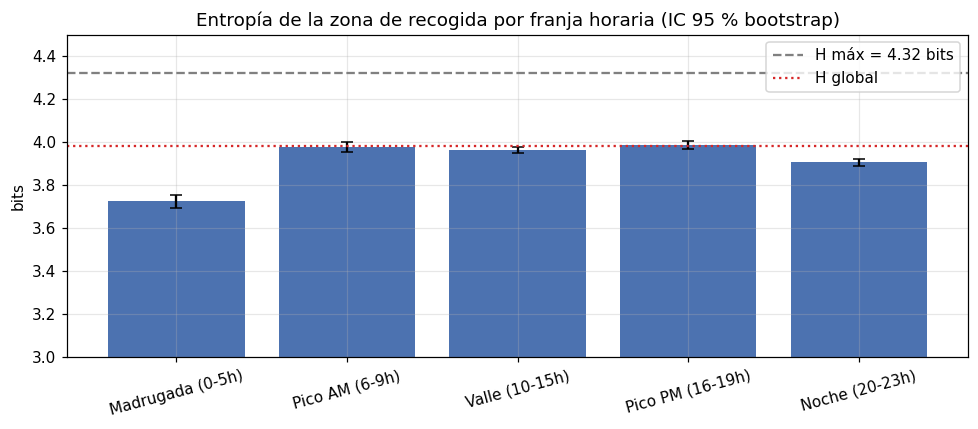

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
t = tabla_H.iloc[1:6]
ax.bar(t["Contexto"], t["H (bits)"], yerr=[t["H (bits)"] - t["IC95 inf"], t["IC95 sup"] - t["H (bits)"]], color="#4C72B0", capsize=4)
ax.axhline(H_max, ls="--", c="gray", label=f"H máx = {H_max:.2f} bits")
ax.axhline(tabla_H.loc[0, "H (bits)"], ls=":", c="C3", label="H global")
ax.set_ylim(3, 4.5); ax.set_ylabel("bits"); ax.set_title("Entropía de la zona de recogida por franja horaria (IC 95 % bootstrap)")
ax.legend(); plt.xticks(rotation=15); plt.tight_layout(); plt.savefig("figuras/rol1_entropia_franja.png", bbox_inches="tight"); plt.show()

### 2.1 Entropía temporal por zona: ¿en qué zonas la demanda es predecible en el tiempo?
Para cada zona calculamos $H(\text{hora}\mid\text{zona}=z)$ sobre las 24 horas ($H_{max}=\log_2 24 = 4.585$ bits). Una entropía baja indica que la demanda de la zona se concentra en pocas horas → se puede **programar** la llegada de conductores; una entropía alta indica demanda repartida durante todo el día → requiere **presencia continua**.

In [7]:
H_hora_zona = (df.groupby("zona_pickup").hora.apply(lambda s: entropia(s.value_counts(normalize=True)))
               .rename("H(hora|zona) bits").to_frame())
H_hora_zona["n"] = df.zona_pickup.value_counts()
H_hora_zona["hora pico"] = df.groupby("zona_pickup").hora.agg(lambda s: s.value_counts().idxmax())
H_hora_zona["% en hora pico"] = df.groupby("zona_pickup").hora.agg(lambda s: s.value_counts(normalize=True).max() * 100)
H_hora_zona = H_hora_zona.sort_values("H(hora|zona) bits")
print(f"H(hora) global = {entropia(df.hora.value_counts(normalize=True)):.3f} bits (máx {np.log2(24):.3f})")
print(H_hora_zona.round(3).to_string())

H(hora) global = 4.466 bits (máx 4.585)
                                    H(hora|zona) bits     n  hora pico  % en hora pico
zona_pickup                                                                           
Z12 Aeropuerto LaGuardia                        4.215  1256         23           7.166
Z15 Aeropuerto JFK                              4.289   811         23           8.385
Z14 Upper West Side                             4.306   917         19           8.724
Z09 Central Park/UWS                            4.313  2087         18           6.996
Z03 Upper East Side Sur                         4.331  4668         18           7.862
Z06 Upper East Side Norte                       4.337  2586         17           7.038
Z08 Lenox Hill (UES)                            4.346  2112          9           6.392
Z13 Upper West Side Norte                       4.367  1167         18           7.883
Z11 Financial District                          4.369  1516         19           7.388
Z02

**Interpretación.** Los **aeropuertos tienen la demanda más predecible en el tiempo** (LaGuardia 4.22 bits, JFK 4.29 bits frente a 4.47 bits globales) con pico a las **23 h** (llegada de vuelos nocturnos): son candidatos a **turnos programados** de conductores. *Midtown Oeste* (4.46 bits) y la zona `Otras` (4.53 bits) tienen demanda repartida en todo el día: requieren **presencia continua** o despacho bajo demanda.

## 3. Entropía condicional: ¿cuánta incertidumbre queda sobre el destino?
Comparamos $H(\text{destino})$ con $H(\text{destino}\mid\text{origen})$, $H(\text{destino}\mid\text{franja})$, $H(\text{destino}\mid\text{hora})$ y $H(\text{destino}\mid\text{origen},\text{franja})$. Se verifica además la **regla de la cadena** $H(X,Y)=H(X)+H(Y\mid X)$.

In [8]:
Zd, Zp = df.zona_dropoff, df.zona_pickup
orig_franja = Zp + " | " + df.franja
H_d = entropia(Zd.value_counts(normalize=True))
cond = {
    "H(destino)": H_d,
    "H(destino | franja)": entropia_condicional(Zd, df.franja),
    "H(destino | hora 24h)": entropia_condicional(Zd, df.hora),
    "H(destino | fin de semana)": entropia_condicional(Zd, df.fin_de_semana),
    "H(destino | origen)": entropia_condicional(Zd, Zp),
    "H(destino | origen, franja)": entropia_condicional(Zd, orig_franja),
}
tabla_cond = pd.DataFrame({"bits": cond}); tabla_cond["reducción vs H(destino)"] = H_d - tabla_cond.bits
tabla_cond["% reducción"] = 100 * tabla_cond["reducción vs H(destino)"] / H_d
print(tabla_cond.round(4).to_string())

# Regla de la cadena
H_p = entropia(Zp.value_counts(normalize=True)); H_pd = entropia_conjunta(Zp, Zd)
print(f"\nRegla de la cadena: H(origen,destino) = {H_pd:.4f}  |  H(origen) + H(destino|origen) = {H_p + cond['H(destino | origen)']:.4f}")

                               bits  reducción vs H(destino)  % reducción
H(destino)                   3.9468                   0.0000       0.0000
H(destino | franja)          3.8874                   0.0594       1.5057
H(destino | hora 24h)        3.8688                   0.0780       1.9759
H(destino | fin de semana)   3.9401                   0.0066       0.1679
H(destino | origen)          3.6671                   0.2796       7.0855
H(destino | origen, franja)  3.5814                   0.3654       9.2581

Regla de la cadena: H(origen,destino) = 7.6479  |  H(origen) + H(destino|origen) = 7.6479


**Interpretación.** Saber la **zona de origen** reduce la incertidumbre del destino en **0.28 bits (7.1 %)**, mientras que la hora sola la reduce solo 0.078 bits (2.0 %) y el tipo de día apenas 0.007 bits (0.17 %). Combinando origen y franja se llega a **9.3 %**. La regla de la cadena se verifica exactamente (7.6479 = 7.6479 bits). Conclusión: para anticipar **dónde terminará un viaje** (y dónde quedará libre el conductor), el origen informa ~3.6 veces más que la hora.

## 4. Información mutua: ¿cuántos bits aporta la hora sobre el destino?
$I(X;Y)$ con estimador *plug-in* tiene **sesgo positivo** en muestras finitas (aprox. $\frac{(|X|-1)(|Y|-1)}{2N\ln 2}$ bits). Para asegurar que las MI pequeñas no son ruido hacemos una **prueba de permutación** (200 permutaciones de $X$): si la hora no tuviera relación con el destino, ¿qué MI veríamos por azar?

In [9]:
def mi_con_permutacion(x, y, B=200, seed=1):
    r = np.random.default_rng(seed)
    obs = info_mutua(x, y)
    nulo = np.array([info_mutua(pd.Series(r.permutation(x.values)), y.reset_index(drop=True)) for _ in range(B)])
    sesgo_teo = (x.nunique() - 1) * (y.nunique() - 1) / (2 * len(x) * np.log(2))
    return obs, nulo.mean(), np.percentile(nulo, 99), (nulo >= obs).mean(), sesgo_teo

pares = {
    "I(hora 24h ; destino)": (df.hora, Zd),
    "I(franja ; destino)": (df.franja, Zd),
    "I(fin de semana ; destino)": (df.fin_de_semana, Zd),
    "I(hora 24h ; origen)": (df.hora, Zp),
    "I(origen ; destino)": (Zp, Zd),
}
filas = []
for nombre, (x, y) in pares.items():
    obs, nulo_m, nulo_99, pval, sesgo = mi_con_permutacion(x.reset_index(drop=True), y.reset_index(drop=True))
    filas.append([nombre, obs, nulo_m, nulo_99, pval, obs - nulo_m, 100 * (obs - nulo_m) / H_d])
tabla_MI = pd.DataFrame(filas, columns=["Par", "MI obs (bits)", "MI nula media", "MI nula p99", "p-valor", "MI corregida", "% de H(destino)"])
print(tabla_MI.round(4).to_string(index=False))

                       Par  MI obs (bits)  MI nula media  MI nula p99  p-valor  MI corregida  % de H(destino)
     I(hora 24h ; destino)         0.0780         0.0063       0.0074      0.0        0.0716           1.8150
       I(franja ; destino)         0.0594         0.0011       0.0016      0.0        0.0583           1.4775
I(fin de semana ; destino)         0.0066         0.0003       0.0005      0.0        0.0064           0.1609
      I(hora 24h ; origen)         0.0659         0.0063       0.0076      0.0        0.0596           1.5090
       I(origen ; destino)         0.2796         0.0053       0.0063      0.0        0.2744           6.9523


**Interpretación.**
- **Todas las MI son significativas** (ninguna de las 200 permutaciones alcanzó el valor observado, p < 0.005).
- $I(\text{hora};\text{destino}) = 0.078$ bits, de los cuales ~0.006 bits son sesgo muestral: la MI corregida es **0.072 bits** (1.8 % de $H(\text{destino})$). La hora **sí** aporta información sobre el destino, pero poca.
- $I(\text{origen};\text{destino}) = 0.280$ bits (corregida 0.274) es **3.8 veces mayor** que la de la hora: los pares origen-destino (corredores) son la estructura más informativa del sistema.
- $I(\text{fin de semana};\text{destino}) = 0.0066$ bits: el tipo de día casi no cambia *a dónde* va la gente.

In [10]:
# MI hora-destino separada por tipo de día: ¿la hora informa más en días laborales?
for etiqueta, d in [("Laboral", df[df.fin_de_semana == 0]), ("Fin de semana", df[df.fin_de_semana == 1])]:
    print(f"{etiqueta:14s} I(hora; destino) = {info_mutua(d.hora, d.zona_dropoff):.4f} bits | "
          f"I(origen; destino) = {info_mutua(d.zona_pickup, d.zona_dropoff):.4f} bits  (n={len(d)})")

Laboral        I(hora; destino) = 0.0908 bits | I(origen; destino) = 0.2857 bits  (n=35821)
Fin de semana  I(hora; destino) = 0.0801 bits | I(origen; destino) = 0.2829 bits  (n=14179)


En días laborales la hora aporta algo más de información sobre el destino (0.091 vs 0.080 bits): el patrón commuter (casa→trabajo en la mañana) es más marcado de lunes a viernes.

## 5. Divergencia KL: ¿qué tan distinta es la demanda laboral vs. fin de semana?
Calculamos $D_{KL}$ en **ambas direcciones** (no es simétrica) y la divergencia de Jensen-Shannon (simétrica, acotada en [0,1] bit) para:
1. la distribución de **zonas de recogida**,
2. la distribución **horaria** (24 h) de la demanda.

In [11]:
lab, fds = df[df.fin_de_semana == 0], df[df.fin_de_semana == 1]
HORAS = list(range(24))
def js(p, q): m = (np.asarray(p) + np.asarray(q)) / 2; return 0.5 * kl(p, m) + 0.5 * kl(q, m)

res_kl = {}
for var, soporte in [("zona_pickup", ZONAS), ("hora", HORAS)]:
    P = distribucion(lab[var], soporte, alpha=1); Q = distribucion(fds[var], soporte, alpha=1)
    res_kl[var] = {"KL(lab||fds)": kl(P, Q), "KL(fds||lab)": kl(Q, P), "JS": js(P, Q)}
    # IC bootstrap de KL(lab||fds)
    r = np.random.default_rng(3); vals = []
    for _ in range(300):
        a = lab[var].iloc[r.integers(0, len(lab), len(lab))]; b = fds[var].iloc[r.integers(0, len(fds), len(fds))]
        vals.append(kl(distribucion(a, soporte, 1), distribucion(b, soporte, 1)))
    res_kl[var]["IC95"] = tuple(np.percentile(vals, [2.5, 97.5]).round(4))
tabla_KL = pd.DataFrame(res_kl).T
print(tabla_KL.to_string())

            KL(lab||fds) KL(fds||lab)        JS              IC95
zona_pickup     0.037799     0.040232  0.009686  (0.0335, 0.0457)
hora             0.15882     0.177634  0.040233  (0.1466, 0.1734)


**Interpretación.**
- En **zonas**: $D_{KL}(\text{lab}\|\text{fds}) = 0.038$ bits (IC95 0.034–0.046) — laboral y fin de semana usan casi las mismas zonas.
- En **horas**: $D_{KL}(\text{lab}\|\text{fds}) = 0.159$ bits (IC95 0.147–0.173), **4.2 veces mayor**. La diferencia de negocio entre laboral y fin de semana es **temporal, no espacial**: no hace falta otro mapa de despliegue para el fin de semana, sino otro **horario**.
- La asimetría ($0.178$ en la dirección fds‖lab) indica que el modelo laboral “sorprende” más al explicar el fin de semana que al revés (la madrugada del fin de semana tiene mucha más demanda de la que el modelo laboral espera).

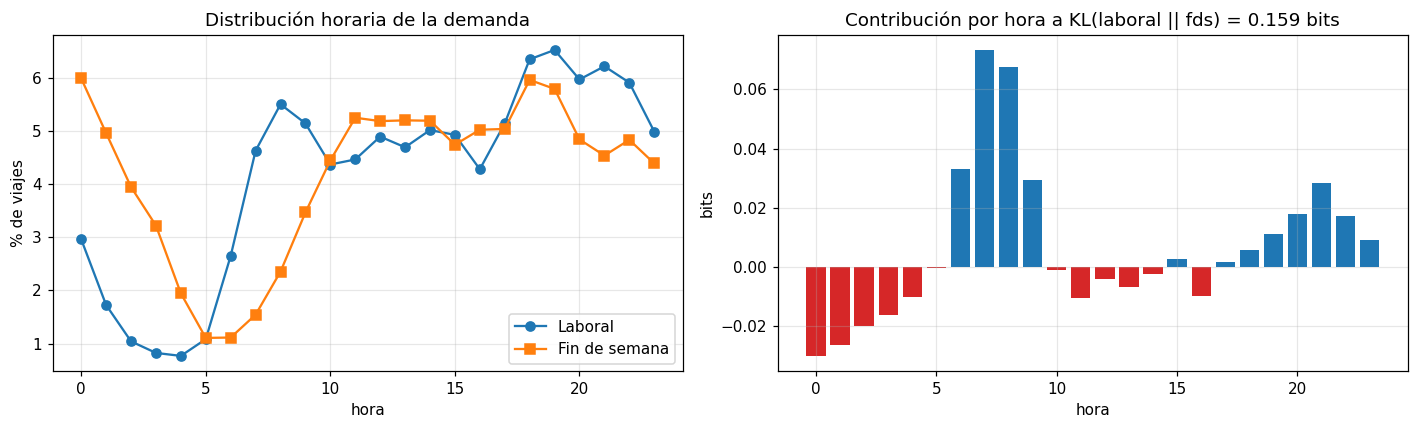

Horas que más aportan a la KL:
 hora
7     0.0733
8     0.0674
6     0.0331
9     0.0292
21    0.0282


In [12]:
P_h = distribucion(lab.hora, HORAS, 1); Q_h = distribucion(fds.hora, HORAS, 1)
contrib = P_h * np.log2(P_h / Q_h)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(HORAS, P_h * 100, "o-", label="Laboral"); axs[0].plot(HORAS, Q_h * 100, "s-", label="Fin de semana")
axs[0].set_xlabel("hora"); axs[0].set_ylabel("% de viajes"); axs[0].set_title("Distribución horaria de la demanda"); axs[0].legend()
axs[1].bar(HORAS, contrib, color=np.where(contrib > 0, "C0", "C3"))
axs[1].set_title(f"Contribución por hora a KL(laboral || fds) = {contrib.sum():.3f} bits"); axs[1].set_xlabel("hora"); axs[1].set_ylabel("bits")
plt.tight_layout(); plt.savefig("figuras/rol1_kl_horas.png", bbox_inches="tight"); plt.show()
print("Horas que más aportan a la KL:\n", contrib.sort_values(ascending=False).head(5).round(4).to_string())

Las horas **6 a 9 a. m.** aportan 0.203 bits, más que la KL total (0.159): el pico commuter laboral, que no existe el fin de semana, es la fuente de la divergencia (las horas de madrugada aportan contribuciones negativas porque allí el fin de semana supera al laboral).

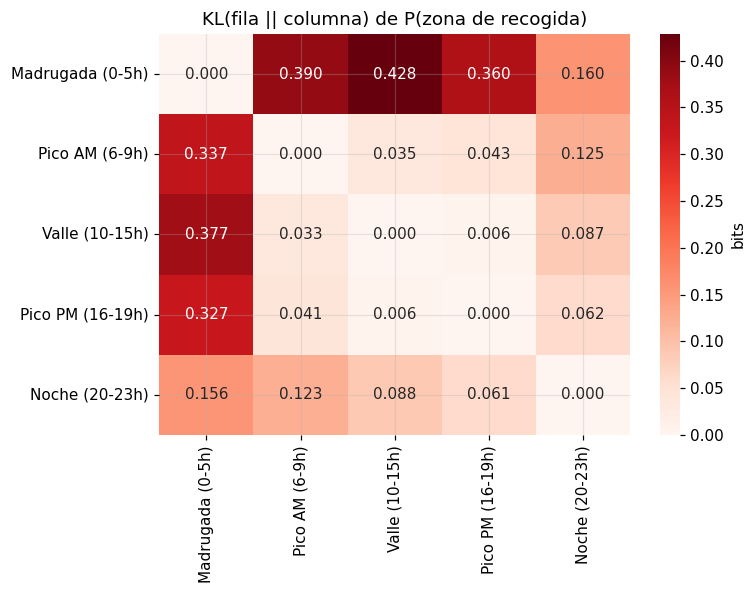

In [13]:
# Matriz de KL entre franjas (distribución de zonas de recogida): ¿qué franjas requieren un despliegue distinto?
M = pd.DataFrame(index=FRANJAS, columns=FRANJAS, dtype=float)
for a in FRANJAS:
    for b in FRANJAS:
        M.loc[a, b] = kl(distribucion(df[df.franja == a].zona_pickup, ZONAS, 1), distribucion(df[df.franja == b].zona_pickup, ZONAS, 1))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(M, annot=True, fmt=".3f", cmap="Reds", ax=ax, cbar_kws={"label": "bits"})
ax.set_title("KL(fila || columna) de P(zona de recogida)"); plt.tight_layout(); plt.savefig("figuras/rol1_kl_franjas.png", bbox_inches="tight"); plt.show()

**Interpretación.** Las franjas diurnas son casi intercambiables entre sí (KL entre 0.006 y 0.043 bits), pero la **madrugada** diverge de todas (0.33–0.43 bits, **10 veces más**). Recomendación directa: UrbanMove necesita **dos mapas de posicionamiento** (diurno y madrugada) y uno de transición para la noche (20–23 h, KL ≈ 0.06–0.16 bits).

## 6. Entropía cruzada: el costo de usar el modelo equivocado
**(a) Costo de un modelo único.** Si UrbanMove usa la distribución laboral $Q$ para anticipar la demanda del fin de semana $P$, paga $H(P,Q) = H(P) + D_{KL}(P\|Q)$ bits por viaje en lugar de $H(P)$.

**(b) Entropía cruzada como métrica predictiva (log-loss).** Dividimos la muestra en entrenamiento (70 %) y prueba (30 %) y medimos cuántos bits por viaje necesita cada modelo para predecir la **zona de destino** en datos no vistos (menos bits = mejor predicción, es exactamente la *cross-entropy loss* que se usa en ML).

In [14]:
for var, soporte, nombre in [("zona_pickup", ZONAS, "zona"), ("hora", HORAS, "hora")]:
    P = distribucion(fds[var], soporte, 1); Q = distribucion(lab[var], soporte, 1)
    print(f"[{nombre}] H(P_fds) = {entropia(P):.4f} | H(P_fds, Q_lab) = {entropia_cruzada(P, Q):.4f} | "
          f"diferencia = KL = {entropia_cruzada(P, Q) - entropia(P):.4f} bits ({100*(entropia_cruzada(P, Q)/entropia(P)-1):.2f} % extra)")

[zona] H(P_fds) = 3.9861 | H(P_fds, Q_lab) = 4.0263 | diferencia = KL = 0.0402 bits (1.01 % extra)
[hora] H(P_fds) = 4.4764 | H(P_fds, Q_lab) = 4.6541 | diferencia = KL = 0.1776 bits (3.97 % extra)


**Interpretación (a).** Usar el modelo laboral para el fin de semana cuesta **0.040 bits extra por viaje en zonas (+1.0 %)** pero **0.178 bits en horas (+4.0 %)**. De nuevo: el horario es lo que hay que ajustar por tipo de día.

In [15]:
idx = rng.permutation(len(df)); corte = int(.7 * len(df))
tr, te = df.iloc[idx[:corte]], df.iloc[idx[corte:]]

def ce_condicional(tr, te, condicion, alpha=1.0):
    # Log-loss (bits/viaje) de P(destino | condición) estimado en train con Laplace, evaluado en test
    K = len(ZONAS); zi = {z: i for i, z in enumerate(ZONAS)}
    if condicion is None:
        p = distribucion(tr.zona_dropoff, ZONAS, alpha)
        return -np.mean(np.log2(p.loc[te.zona_dropoff].values))
    cnt = pd.crosstab(tr[condicion], tr.zona_dropoff).reindex(columns=ZONAS, fill_value=0)
    probs = (cnt + alpha).div(cnt.sum(axis=1) + alpha * K, axis=0)
    marg = distribucion(tr.zona_dropoff, ZONAS, alpha)
    ll = []
    for c, z in zip(te[condicion], te.zona_dropoff):
        ll.append(np.log2(probs.at[c, z] if c in probs.index else marg[z]))
    return -np.mean(ll)

tr = tr.assign(orig_franja=tr.zona_pickup + "|" + tr.franja); te = te.assign(orig_franja=te.zona_pickup + "|" + te.franja)
modelos = {"Uniforme (sin información)": np.log2(len(ZONAS)),
           "P(destino)": ce_condicional(tr, te, None),
           "P(destino | franja)": ce_condicional(tr, te, "franja"),
           "P(destino | hora)": ce_condicional(tr, te, "hora"),
           "P(destino | origen)": ce_condicional(tr, te, "zona_pickup"),
           "P(destino | origen, franja)": ce_condicional(tr, te, "orig_franja")}
tabla_CE = pd.DataFrame({"Entropía cruzada test (bits/viaje)": modelos})
tabla_CE["Ganancia vs P(destino)"] = modelos["P(destino)"] - tabla_CE.iloc[:, 0]
tabla_CE["Destinos efectivos 2^CE"] = 2 ** tabla_CE.iloc[:, 0]
print(tabla_CE.round(4).to_string())

                             Entropía cruzada test (bits/viaje)  Ganancia vs P(destino)  Destinos efectivos 2^CE
Uniforme (sin información)                               4.3219                 -0.3708                  20.0000
P(destino)                                               3.9511                  0.0000                  15.4667
P(destino | franja)                                      3.8967                  0.0544                  14.8946
P(destino | hora)                                        3.8922                  0.0589                  14.8483
P(destino | origen)                                      3.6913                  0.2598                  12.9181
P(destino | origen, franja)                              3.6553                  0.2958                  12.5995


**Interpretación (b).** En datos **no vistos**, el modelo $P(\text{destino}\mid\text{origen},\text{franja})$ reduce la entropía cruzada de 3.951 a **3.655 bits/viaje** (−0.296 bits): el número de destinos efectivos baja de **15.5 a 12.6**. La hora sola solo gana 0.059 bits. La ganancia en test (0.296) es algo menor que la reducción en entrenamiento (0.365 bits de la sección 3): la diferencia es el sobreajuste de estimar 100 distribuciones condicionales con 35 000 viajes — por eso usamos suavizado de Laplace.

## 7. Desigualdad de Jensen
Para $f$ convexa: $f(\mathbb{E}[X]) \le \mathbb{E}[f(X)]$; para $f$ cóncava la desigualdad se invierte.

**(a) Por qué la KL nunca es negativa (Gibbs).** Con $\log$ cóncava: $-D_{KL}(P\|Q) = \mathbb{E}_P\left[\log\frac{q}{p}\right] \le \log \mathbb{E}_P\left[\frac{q}{p}\right] = \log\sum q = 0$. Lo verificamos con nuestras distribuciones reales.

**(b) Aplicación de negocio — el ETA con velocidad promedio.** El tiempo por km es $1/V$ (convexa en $V$). Por Jensen, $\mathbb{E}[1/V] \ge 1/\mathbb{E}[V]$: estimar el tiempo de llegada dividiendo la distancia entre la velocidad promedio **subestima sistemáticamente** el tiempo real.

**(c) Media geométrica vs. aritmética de la duración.** $\log$ es cóncava → $\mathbb{E}[\log T] \le \log\mathbb{E}[T]$: un modelo entrenado en escala logarítmica (habitual en duraciones) reporta la media geométrica, que es menor que la media aritmética que paga el cliente.

In [16]:
# (a) Verificación numérica de Jensen dentro de la KL
P = distribucion(lab.zona_pickup, ZONAS, 1).values; Q = distribucion(fds.zona_pickup, ZONAS, 1).values
lado_izq = np.sum(P * np.log2(Q / P))           # E_P[log q/p] = -KL
lado_der = np.log2(np.sum(P * (Q / P)))          # log E_P[q/p] = log 1 = 0
print(f"(a) E_P[log2(q/p)] = {lado_izq:.5f}  <=  log2 E_P[q/p] = {lado_der:.5f}  -> KL = {-lado_izq:.5f} >= 0")

# (b) Ritmo (min/km) real vs. el implícito en la velocidad promedio
V = df.vel_kmh
ritmo_real = (60 / V).mean()                    # E[60/V]  (min por km)
ritmo_jensen = 60 / V.mean()                     # 60 / E[V]
dist_media = df.dist_km.mean()
print(f"(b) E[V] = {V.mean():.2f} km/h | 60/E[V] = {ritmo_jensen:.3f} min/km | E[60/V] = {ritmo_real:.3f} min/km")
print(f"    Brecha de Jensen: {ritmo_real - ritmo_jensen:.3f} min/km ({100*(ritmo_real/ritmo_jensen-1):.1f} %) "
      f"-> en un viaje medio de {dist_media:.2f} km el ETA ingenuo subestima {dist_media*(ritmo_real-ritmo_jensen):.2f} min")

# (c) Media aritmética vs geométrica de la duración
T = df.duracion_min
print(f"(c) log E[T] = {np.log(T.mean()):.4f} >= E[log T] = {np.log(T).mean():.4f} | "
      f"media aritmética = {T.mean():.2f} min vs geométrica = {np.exp(np.log(T).mean()):.2f} min")

# Brecha de Jensen del ritmo por franja (dónde el ETA ingenuo falla más)
brecha = df.groupby("franja").vel_kmh.agg(lambda v: (60 / v).mean() - 60 / v.mean()).reindex(FRANJAS)
vel = df.groupby("franja").vel_kmh.mean().reindex(FRANJAS)
print("\nPor franja:\n", pd.DataFrame({"vel media km/h": vel, "brecha Jensen min/km": brecha}).round(3).to_string())

(a) E_P[log2(q/p)] = -0.03780  <=  log2 E_P[q/p] = -0.00000  -> KL = 0.03780 >= 0
(b) E[V] = 14.46 km/h | 60/E[V] = 4.148 min/km | E[60/V] = 5.591 min/km
    Brecha de Jensen: 1.443 min/km (34.8 %) -> en un viaje medio de 3.45 km el ETA ingenuo subestima 4.97 min
(c) log E[T] = 2.6395 >= E[log T] = 2.3856 | media aritmética = 14.01 min vs geométrica = 10.87 min

Por franja:
                   vel media km/h  brecha Jensen min/km
franja                                                
Madrugada (0-5h)          19.473                 0.862
Pico AM (6-9h)            14.698                 1.512
Valle (10-15h)            12.250                 1.728
Pico PM (16-19h)          12.872                 1.335
Noche (20-23h)            16.085                 0.986


**Interpretación.**
- (a) Se verifica numéricamente la desigualdad de Gibbs: $-D_{KL} = -0.0378 \le 0$.
- (b) **Hallazgo de negocio:** la velocidad promedio es 14.46 km/h, lo que sugiere 4.15 min/km; pero el ritmo promedio real es **5.59 min/km**. Un ETA calculado como distancia / velocidad promedio **subestima el tiempo en 34.8 %**, es decir **~5.0 minutos en un viaje medio de 3.45 km**. La brecha es máxima en el **valle (10–15 h): 1.73 min/km**, cuando el tráfico es más heterogéneo. UrbanMove debe estimar ETA y tarifas con el **ritmo** (min/km) por franja, no con la velocidad media.
- (c) La media aritmética de la duración (14.0 min) supera a la geométrica (10.9 min): un modelo en escala log reporta ~3 minutos menos por viaje.

## 8. Log-sum-exp trick: combinar muchas probabilidades sin pérdida numérica
$$\log\sum_k e^{a_k} = m + \log\sum_k e^{a_k - m}, \qquad m = \max_k a_k$$

**Caso de negocio: ¿este día fue laboral o de fin de semana?** Tomamos *todos* los viajes de un día concreto de la muestra y calculamos la verosimilitud de su secuencia de zonas de recogida bajo dos modelos: $P_{lab}$ y $P_{fds}$ (estimados sin ese día). La probabilidad posterior es
$$P(\text{fds}\mid \text{viajes}) = \frac{\pi_{fds}\prod_i P_{fds}(z_i)}{\sum_{c}\pi_c\prod_i P_c(z_i)}$$
Con cientos de viajes, $\prod_i P(z_i)$ es del orden de $10^{-300}$ o menor → **underflow a 0** en `float64`, y el cociente da `0/0 = NaN`. Con log-probabilidades + log-sum-exp el cálculo es exacto. Es **el mismo cálculo** que hace el paso E del algoritmo EM del Rol 3 para obtener las responsabilidades.

In [17]:
df["fecha"] = df.pickup_datetime.dt.date
dias = df.groupby("fecha").agg(n=("id", "size"), fds=("fin_de_semana", "first"))
print(f"Días en la muestra: {len(dias)} | viajes por día: min {dias.n.min()}, mediana {dias.n.median():.0f}, máx {dias.n.max()}")

def clasificar_dia(fecha, mostrar=False):
    d = df[df.fecha == fecha]; resto = df[df.fecha != fecha]
    modelos = {c: distribucion(resto[resto.fin_de_semana == c].zona_pickup, ZONAS, 1) for c in (0, 1)}
    prior = {0: 5 / 7, 1: 2 / 7}
    loglik = {c: np.log(prior[c]) + np.log(modelos[c].loc[d.zona_pickup].values).sum() for c in (0, 1)}
    a = np.array([loglik[0], loglik[1]])
    # Ingenuo: exponenciar directamente
    with np.errstate(all="ignore"):
        ingenuo = np.exp(a) / np.exp(a).sum()
    # Log-sum-exp
    post = np.exp(a - logsumexp(a))
    if mostrar:
        print(f"Día {fecha} ({'fin de semana' if d.fin_de_semana.iloc[0] else 'laboral'}), {len(d)} viajes")
        print(f"  log P(viajes, lab) = {a[0]:.2f} nats | log P(viajes, fds) = {a[1]:.2f} nats")
        print(f"  exp() ingenuo -> {np.exp(a)}  => posterior ingenua = {ingenuo}")
        m = a.max(); print(f"  LSE: m = {m:.2f}; log Σ = m + log Σ exp(a - m) = {m + np.log(np.exp(a - m).sum()):.2f} (scipy: {logsumexp(a):.2f})")
        print(f"  Posterior con LSE: P(lab) = {post[0]:.6f}, P(fds) = {post[1]:.6f}")
    return post[1], np.isnan(ingenuo).any()

ej_lab = dias[dias.fds == 0].n.idxmax(); ej_fds = dias[dias.fds == 1].n.idxmax()
clasificar_dia(ej_lab, True); print(); clasificar_dia(ej_fds, True)

Días en la muestra: 182 | viajes por día: min 68, mediana 278, máx 341
Día 2016-01-22 (laboral), 333 viajes
  log P(viajes, lab) = -912.66 nats | log P(viajes, fds) = -914.72 nats
  exp() ingenuo -> [0. 0.]  => posterior ingenua = [nan nan]
  LSE: m = -912.66; log Σ = m + log Σ exp(a - m) = -912.54 (scipy: -912.54)
  Posterior con LSE: P(lab) = 0.887108, P(fds) = 0.112892

Día 2016-04-09 (fin de semana), 341 viajes
  log P(viajes, lab) = -958.56 nats | log P(viajes, fds) = -950.51 nats
  exp() ingenuo -> [0. 0.]  => posterior ingenua = [nan nan]
  LSE: m = -950.51; log Σ = m + log Σ exp(a - m) = -950.50 (scipy: -950.50)
  Posterior con LSE: P(lab) = 0.000317, P(fds) = 0.999683


(np.float64(0.9996832967494127), np.True_)

In [18]:
# Clasificación de TODOS los días de la muestra con log-sum-exp
res = [(f, *clasificar_dia(f)) for f in dias.index]
cls = pd.DataFrame(res, columns=["fecha", "P_fds", "ingenuo_NaN"]).set_index("fecha").join(dias)
cls["pred"] = (cls.P_fds > .5).astype(int)
acc = (cls.pred == cls.fds).mean()
print(f"Días clasificados: {len(cls)} | exactitud usando solo zonas de recogida: {acc:.1%}")
print(f"Días en que el cálculo ingenuo produce NaN (underflow): {cls.ingenuo_NaN.sum()} de {len(cls)}")
print(pd.crosstab(cls.fds, cls.pred, rownames=["real (1=fds)"], colnames=["predicho"]))
print("\nDías mal clasificados:\n", cls[cls.pred != cls.fds][["n", "fds", "P_fds"]].round(4).to_string())

Días clasificados: 182 | exactitud usando solo zonas de recogida: 95.1%
Días en que el cálculo ingenuo produce NaN (underflow): 105 de 182
predicho        0   1
real (1=fds)         
0             128   2
1               7  45

Días mal clasificados:
               n  fds   P_fds
fecha                       
2016-01-01  254    0  0.9912
2016-01-02  245    1  0.0425
2016-01-03  217    1  0.1346
2016-01-24  112    1  0.0449
2016-04-24  245    1  0.1107
2016-05-06  292    0  0.8975
2016-05-15  313    1  0.2009
2016-05-29  214    1  0.0850
2016-06-26  237    1  0.2078


**Interpretación.**
- Con ~300 viajes, la log-verosimilitud de un día es del orden de **−900 nats**; $e^{-900}$ está muy por debajo del mínimo representable en `float64` (~$e^{-745}$), así que el cálculo ingenuo da `[0, 0]` y la posterior `NaN` en **105 de los 182 días**. Con log-sum-exp se obtiene la posterior exacta en todos.
- Solo con la distribución de zonas de recogida clasificamos el tipo de día con **95.1 % de exactitud**. Los errores tienen sentido de negocio: el **1 de enero de 2016** (festivo, viernes) se comporta como fin de semana ($P_{fds}=0.99$); varios domingos de puentes/festivos o con clima extremo (p. ej. 24 de enero de 2016, con solo 112 viajes en la muestra, tras la gran nevada de ese fin de semana) se parecen a un día laboral. Un sistema de despliegue debería tratar los **festivos como fin de semana**.

### 8.1 Puente hacia el Rol 3
En una mezcla gaussiana, la responsabilidad del perfil $k$ para el viaje $i$ es
$\gamma_{ik} = \exp\big(\log\pi_k + \log\mathcal{N}(x_i\mid\mu_k,\Sigma_k) - \text{LSE}_j[\log\pi_j + \log\mathcal{N}(x_i\mid\mu_j,\Sigma_j)]\big)$:
exactamente la misma operación que acabamos de hacer con "laboral" vs "fin de semana". El Rol 3 implementa su paso E con esta fórmula. Además, la **entropía de las responsabilidades** $H(\gamma_i)$ que reporta el Rol 3 mide cuán ambiguo es cada viaje entre perfiles — de nuevo, teoría de la información aplicada.

In [19]:
# Resultados para el documento PDF y para el Rol 4
g = tabla_H.set_index("Contexto")
resultados = {
    "K_zonas": len(ZONAS), "H_max": H_max,
    "H_global": g.loc["Global", "H (bits)"], "zonas_efectivas_global": g.loc["Global", "Zonas efectivas 2^H"],
    "H_por_contexto": g["H (bits)"].round(4).to_dict(),
    "zonas_efectivas_por_contexto": g["Zonas efectivas 2^H"].round(2).to_dict(),
    "top5_share": float(top5),
    "H_destino": H_d, "entropias_condicionales": {k: round(v, 4) for k, v in cond.items()},
    "MI": tabla_MI.set_index("Par")["MI obs (bits)"].round(4).to_dict(),
    "MI_corregida": tabla_MI.set_index("Par")["MI corregida"].round(4).to_dict(),
    "KL_zona": {k: (round(v, 4) if not isinstance(v, tuple) else v) for k, v in res_kl["zona_pickup"].items()},
    "KL_hora": {k: (round(v, 4) if not isinstance(v, tuple) else v) for k, v in res_kl["hora"].items()},
    "CE_test": tabla_CE.iloc[:, 0].round(4).to_dict(),
    "jensen_ritmo_real": ritmo_real, "jensen_ritmo_ingenuo": ritmo_jensen,
    "jensen_subestimacion_min_viaje_medio": dist_media * (ritmo_real - ritmo_jensen),
    "LSE_exactitud_dias": acc, "LSE_dias_nan_ingenuo": int(cls.ingenuo_NaN.sum()), "LSE_dias": len(cls),
    "H_hora_zona": H_hora_zona["H(hora|zona) bits"].round(3).to_dict(),
    "p_zona_franja": p_zona_franja.round(4).to_dict(),
}
utils.guardar_resultados("rol1.json", resultados)
print("Guardado resultados/rol1.json")

Guardado resultados/rol1.json
